# Task 3 — Exploratory Data Analysis (EDA)
**Thiranex Data Science Internship**

## Project: Student Performance and Study Factors Analysis

### Objective
Explore a public student performance dataset to understand score distributions, relationships among subject scores, and patterns associated with study habits and background factors.

**Dataset:** UCI Student Performance dataset (`student-mat.csv`). The notebook uses the Mathematics subject dataset and downloads it automatically.

## 1. Import libraries

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")


## 2. Load dataset

In [4]:
import pandas as pd

DATA_URL = "https://huggingface.co/datasets/DElmazi/Student_Performance/resolve/main/student-mat.csv"

df = pd.read_csv(DATA_URL, sep=";")

print("Dataset loaded successfully!")
print("Shape:", df.shape)
df.head()

Dataset loaded successfully!
Shape: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


## 3. Data overview

In [5]:
display(df.describe(include="all").T)
missing = df.isna().sum().sort_values(ascending=False)
display(missing.to_frame("missing values"))
print("Exact duplicate rows:", df.duplicated().sum())


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
school,395,2,GP,349,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sex,395,2,F,208,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,395.0,NaN,NaN,NaN,16.696203,1.276043,15.0,16.0,17.0,18.0,22.0
address,395,2,U,307,NaN,NaN,NaN,NaN,NaN,NaN,NaN
famsize,395,2,GT3,281,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Pstatus,395,2,T,354,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Medu,395.0,NaN,NaN,NaN,2.749367,1.094735,0.0,2.0,3.0,4.0,4.0
Fedu,395.0,NaN,NaN,NaN,2.521519,1.088201,0.0,2.0,2.0,3.0,4.0
Mjob,395,5,other,141,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fjob,395,5,other,217,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,missing values
school,0
sex,0
age,0
address,0
famsize,0
Pstatus,0
Medu,0
Fedu,0
Mjob,0
Fjob,0


Exact duplicate rows: 0


## 4. Basic cleaning

In [6]:
df_clean = df.copy()
# Normalize text values and remove exact duplicate rows
for col in df_clean.select_dtypes(include="object").columns:
    df_clean[col] = df_clean[col].str.strip()
df_clean = df_clean.drop_duplicates().copy()

print("Rows before cleaning:", len(df))
print("Rows after cleaning:", len(df_clean))


Rows before cleaning: 395
Rows after cleaning: 395


## 5. Target score distributions

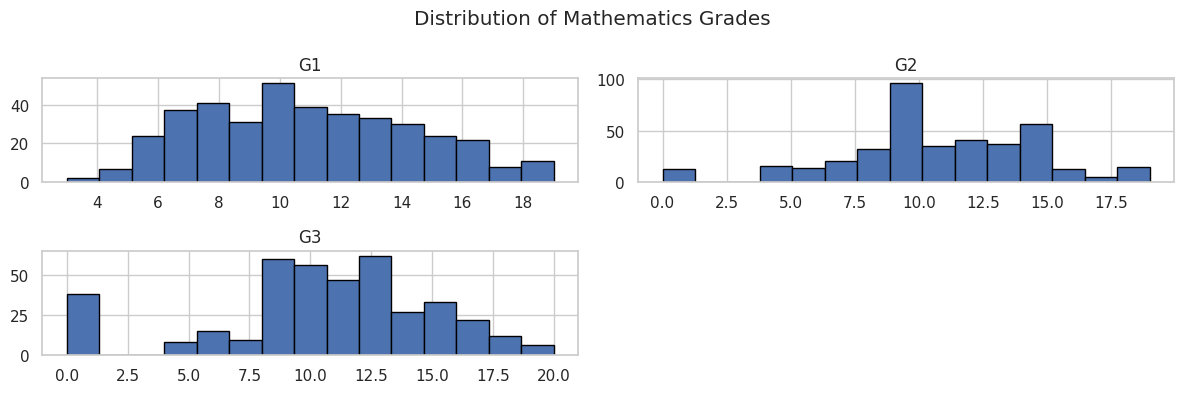

In [7]:
score_cols = ["G1", "G2", "G3"]
df_clean[score_cols].hist(bins=15, figsize=(12, 4), edgecolor="black")
plt.suptitle("Distribution of Mathematics Grades")
plt.tight_layout()
plt.show()


## 6. Correlation analysis

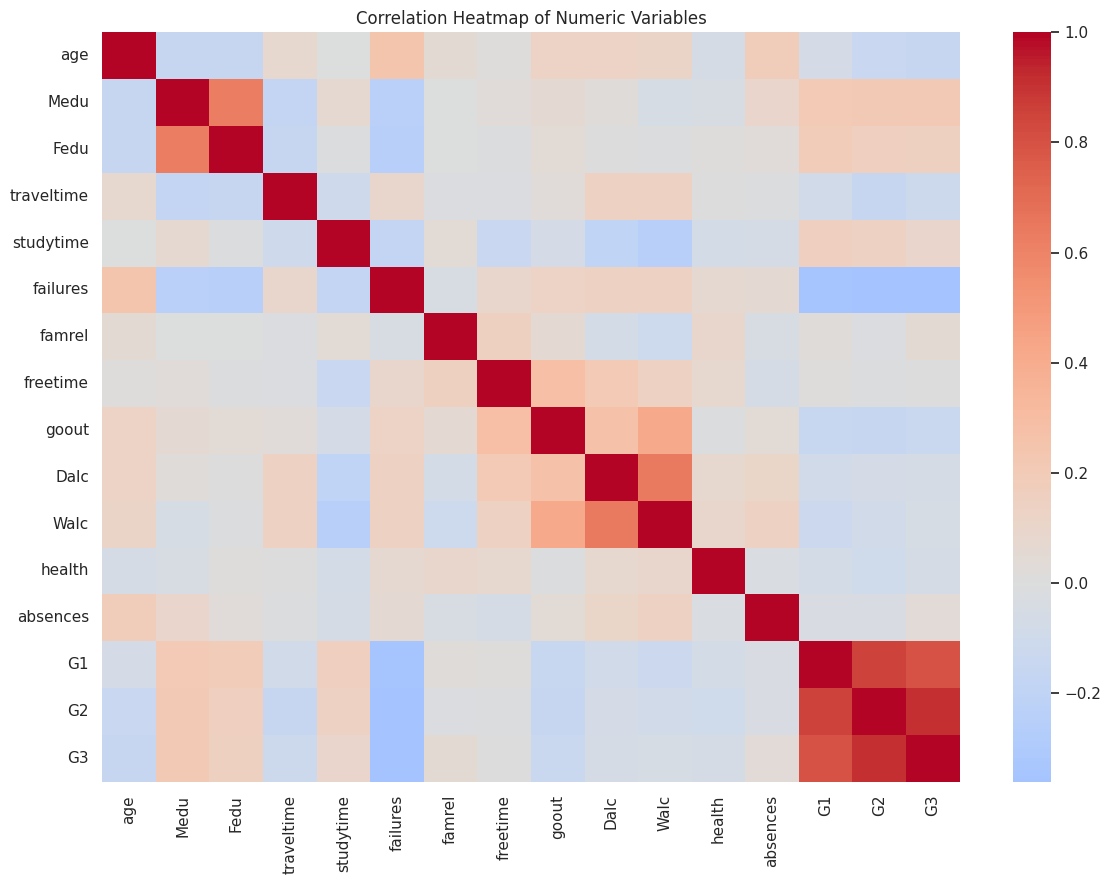

Strongest numeric correlations with final grade G3:


,absolute correlation
G2,0.904868
G1,0.801468
failures,0.360415
Medu,0.217147
age,0.161579
Fedu,0.152457
goout,0.132791
traveltime,0.117142
studytime,0.097820
health,0.061335


In [8]:
numeric_df = df_clean.select_dtypes(include=np.number)
corr = numeric_df.corr()
plt.figure(figsize=(12, 9))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=False)
plt.title("Correlation Heatmap of Numeric Variables")
plt.tight_layout()
plt.show()

print("Strongest numeric correlations with final grade G3:")
display(corr["G3"].drop("G3").abs().sort_values(ascending=False).head(10).to_frame("absolute correlation"))


## 7. Study time and final grade

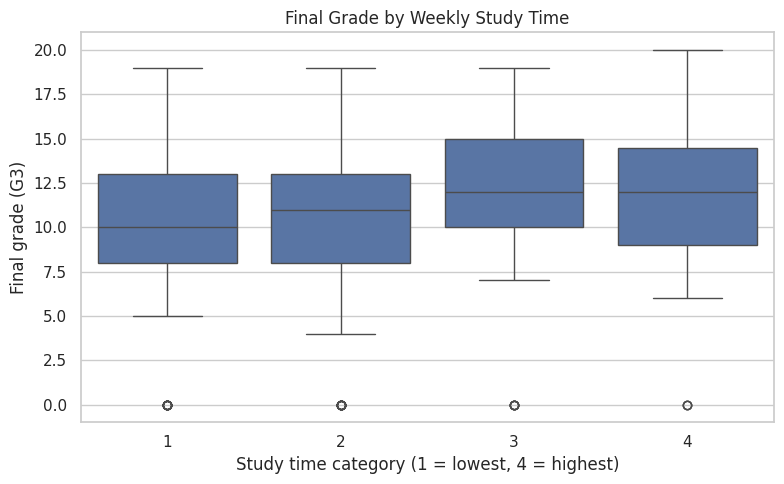

In [9]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_clean, x="studytime", y="G3")
plt.title("Final Grade by Weekly Study Time")
plt.xlabel("Study time category (1 = lowest, 4 = highest)")
plt.ylabel("Final grade (G3)")
plt.tight_layout()
plt.show()


## 8. Absences and final grade

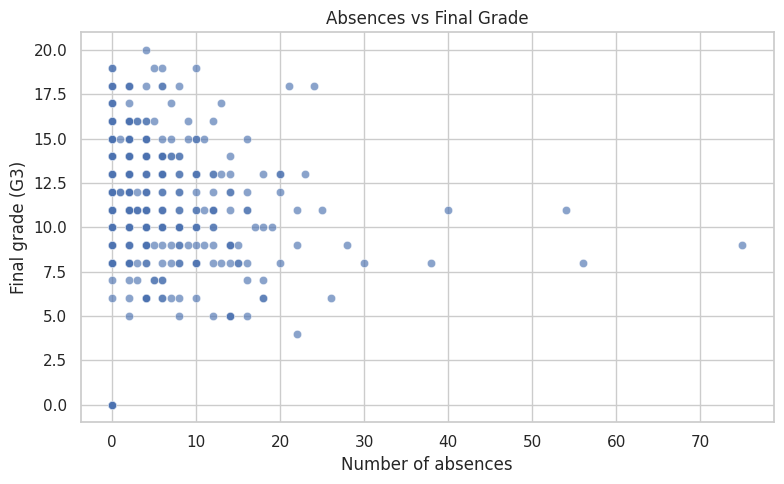

In [10]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_clean, x="absences", y="G3", alpha=0.65)
plt.title("Absences vs Final Grade")
plt.xlabel("Number of absences")
plt.ylabel("Final grade (G3)")
plt.tight_layout()
plt.show()


## 9. Final grade by parental education

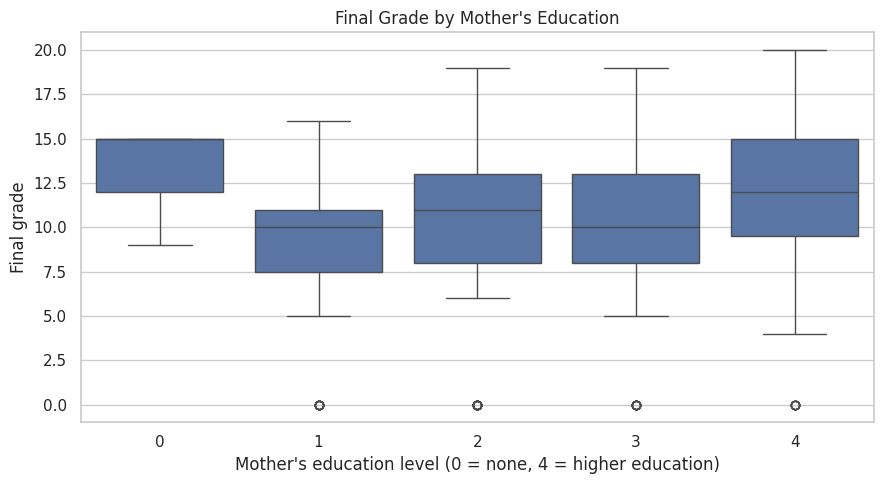

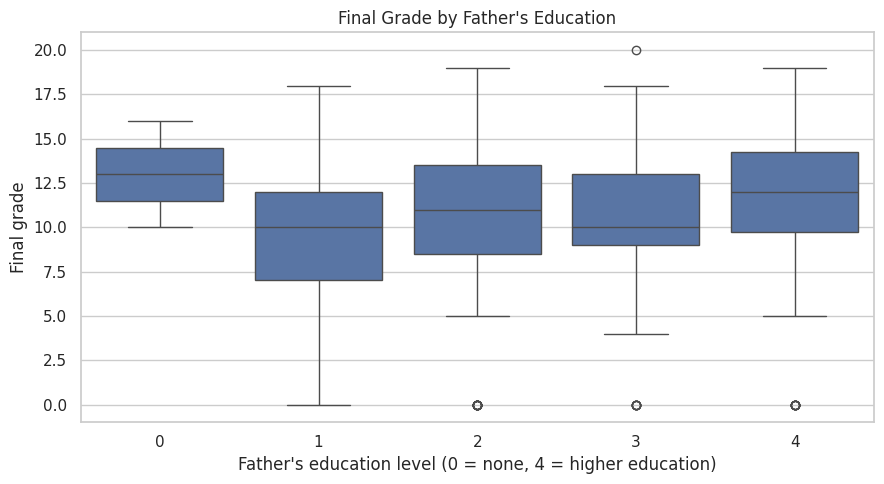

In [11]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=df_clean, x="Medu", y="G3")
plt.title("Final Grade by Mother's Education")
plt.xlabel("Mother's education level (0 = none, 4 = higher education)")
plt.ylabel("Final grade")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))
sns.boxplot(data=df_clean, x="Fedu", y="G3")
plt.title("Final Grade by Father's Education")
plt.xlabel("Father's education level (0 = none, 4 = higher education)")
plt.ylabel("Final grade")
plt.tight_layout()
plt.show()


## 10. Compare grade outcomes by school support

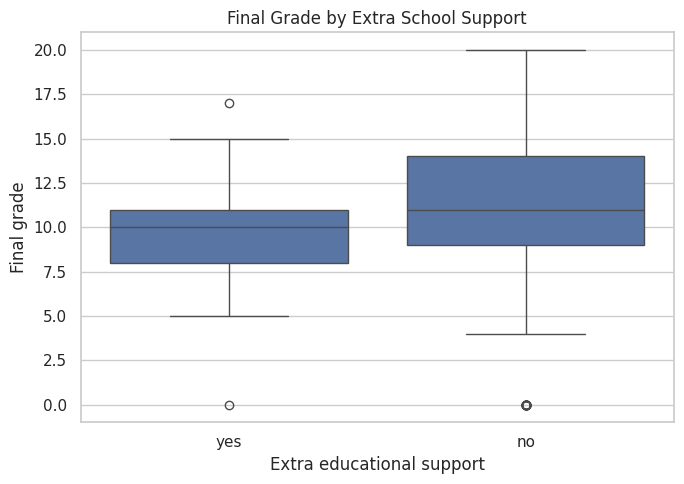

In [12]:
plt.figure(figsize=(7, 5))
sns.boxplot(data=df_clean, x="schoolsup", y="G3")
plt.title("Final Grade by Extra School Support")
plt.xlabel("Extra educational support")
plt.ylabel("Final grade")
plt.tight_layout()
plt.show()


## 11. Grouped summary

In [13]:
study_summary = df_clean.groupby("studytime", observed=True)["G3"].agg(
    ["count", "mean", "median", "std"]
).round(2)
display(study_summary)

support_summary = df_clean.groupby("schoolsup", observed=True)["G3"].agg(
    ["count", "mean", "median"]
).round(2)
display(support_summary)


,count,mean,median,std
studytime,,,,
1,105,10.05,10.0,4.96
2,198,10.17,11.0,4.22
3,65,11.40,12.0,4.64
4,27,11.26,12.0,5.28


,count,mean,median
schoolsup,,,
no,344,10.56,11.0
yes,51,9.43,10.0


## 12. Limitations
- The dataset covers a specific group of students and one subject; it should not be generalized to all schools or populations.
- Observational associations do not establish cause and effect.
- Categories such as study time and parental education are coded ordinal values; interpret them according to the dataset documentation.
- The dataset is a public educational research dataset, not live or current student records.